In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

In [ ]:
torch.manual_seed(42)

In [ ]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"{device}")

 cuda


In [ ]:
df = pd.read_csv('/content/fer2013.csv')
print(df.shape)


(6626, 3)


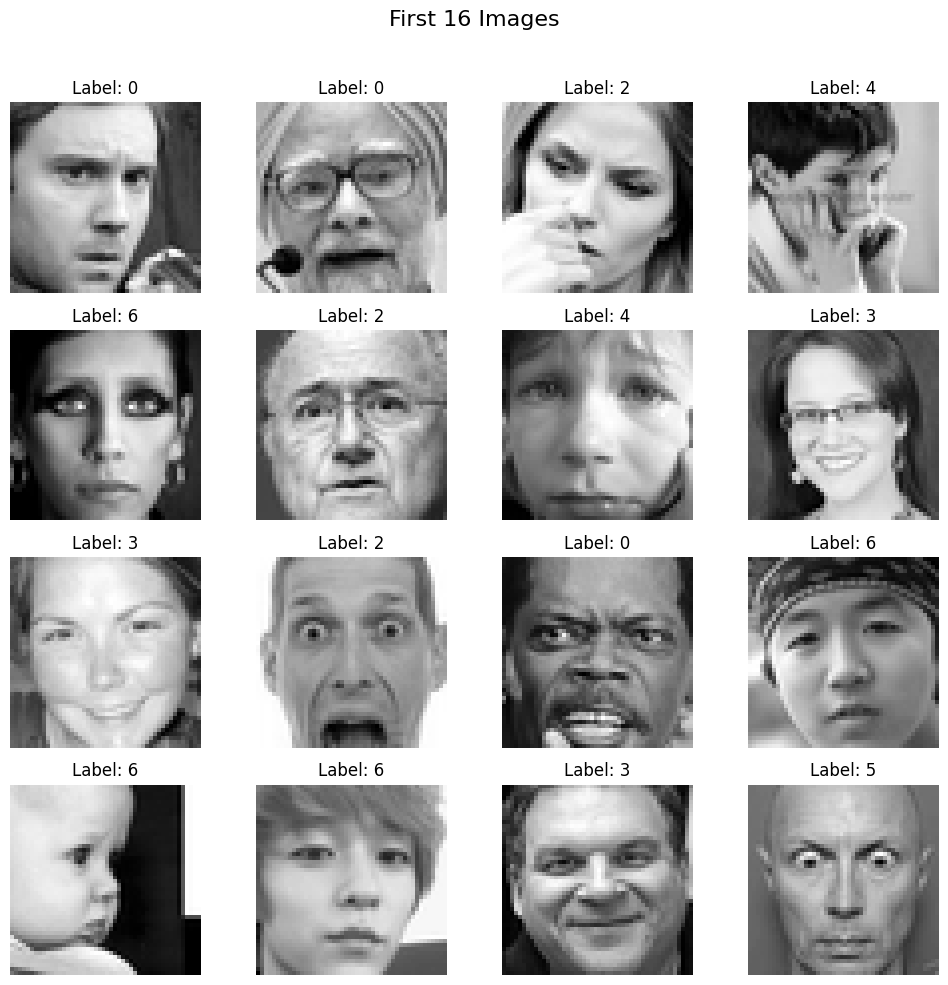

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(4, 4, figsize=(10, 10))
fig.suptitle("First 16 Images", fontsize=16)

for i, ax in enumerate(axes.flat):
    img = np.fromstring(df.iloc[i, 1], sep=' ').reshape(48, 48)

    ax.imshow(img, cmap='gray')
    ax.axis('off')
    ax.set_title(f"Label: {df.iloc[i, 0]}")

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader

class FERDataset(Dataset):
    def __init__(self, df):
        self.df = df.reset_index(drop=True)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        pixels = torch.tensor(
            [int(p) for p in self.df.loc[index, 'pixels'].split()],
            dtype=torch.float32
        ).reshape(1, 48, 48) / 255.0

        label = torch.tensor(
            self.df.loc[index, 'emotion'],
            dtype=torch.long
        )

        return pixels, label

In [ ]:
from sklearn.model_selection import train_test_split

# Drop rows where 'Usage' or other essential columns are missing, if any
clean_df = df.dropna(subset=['emotion', 'pixels']).reset_index(drop=True)

# Perform an 80/10/10 split
train_df, temp_df = train_test_split(clean_df, test_size=0.20, random_state=42, stratify=clean_df['emotion'])
val_df, test_df = train_test_split(temp_df, test_size=0.50, random_state=42, stratify=temp_df['emotion'])

print(f"Train size: {len(train_df)}, Val size: {len(val_df)}, Test size: {len(test_df)}")

train_dataset = FERDataset(train_df)
val_dataset   = FERDataset(val_df)
test_dataset  = FERDataset(test_df)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
val_loader   = DataLoader(val_dataset,   batch_size=64, shuffle=False)
test_loader  = DataLoader(test_dataset,  batch_size=64, shuffle=False)

Train size: 5300, Val size: 663, Test size: 663


In [ ]:
import torch.optim as optim

class FERNet(nn.Module):
    def __init__(self, input_features=1, num_classes=7):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(input_features, 32, kernel_size=3, padding='same'),
            nn.ReLU(),
            nn.BatchNorm2d(32),
            nn.MaxPool2d(2, 2),          # 48 -> 24

            nn.Conv2d(32, 64, kernel_size=3, padding='same'),
            nn.ReLU(),
            nn.BatchNorm2d(64),
            nn.MaxPool2d(2, 2),          # 24 -> 12
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 12 * 12, 128),
            nn.ReLU(),
            nn.Dropout(0.4),

            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.4),

            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        return self.classifier(self.features(x))

model = FERNet().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr=0.01, weight_decay=1e-4)
epochs = 30

In [ ]:
for epoch in range(epochs):

  total_epoch_loss = 0

  for batch_features, batch_labels in train_loader:

    # move data to gpu
    batch_features, batch_labels = batch_features.to(device), batch_labels.to(device)

    # forward pass
    outputs = model(batch_features)

    # calculate loss
    loss = criterion(outputs, batch_labels)

    # back pass
    optimizer.zero_grad()
    loss.backward()

    # update grads
    optimizer.step()

    total_epoch_loss = total_epoch_loss + loss.item()

  avg_loss = total_epoch_loss/len(train_loader)
  print(f'Epoch: {epoch + 1} , Loss: {avg_loss}')

Epoch: 1 , Loss: 1.6852073199473894
Epoch: 2 , Loss: 1.5770420787426143
Epoch: 3 , Loss: 1.4847299777544463
Epoch: 4 , Loss: 1.40272061756024
Epoch: 5 , Loss: 1.2993745872607598
Epoch: 6 , Loss: 1.206532943707246
Epoch: 7 , Loss: 1.0986487590349638
Epoch: 8 , Loss: 0.9506678053965936
Epoch: 9 , Loss: 0.8247791540164214
Epoch: 10 , Loss: 0.6896401079228291
Epoch: 11 , Loss: 0.537371039390564
Epoch: 12 , Loss: 0.3833193299002372
Epoch: 13 , Loss: 0.2791413846067511
Epoch: 14 , Loss: 0.19683302437456754
Epoch: 15 , Loss: 0.07647421522639118
Epoch: 16 , Loss: 0.1554126021398518
Epoch: 17 , Loss: 0.11353159746011862
Epoch: 18 , Loss: 0.07647666974494663
Epoch: 19 , Loss: 0.02437112230556802
Epoch: 20 , Loss: 0.015000677083242828
Epoch: 21 , Loss: 0.009706729193567298
Epoch: 22 , Loss: 0.013155188946536956
Epoch: 23 , Loss: 0.01109024558256631
Epoch: 24 , Loss: 0.008067577685533952
Epoch: 25 , Loss: 0.009460227039548604
Epoch: 26 , Loss: 0.0067809159115243415
Epoch: 27 , Loss: 0.004913414172

In [ ]:
model.eval()

FERNet(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=same)
    (1): ReLU()
    (2): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=same)
    (5): ReLU()
    (6): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=9216, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.4, inplace=False)
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): ReLU()
    (6): Dropout(p=0.4, inplace=False)
    (7): Linear(in_features=64, out_features=7, bias=True)
  )
)

In [ ]:
#evaluation code
total = 0
correct = 0
model.eval()

with torch.no_grad():
  for batch_features, batch_labels in val_loader:
    batch_features, batch_labels = batch_features.to(device), batch_labels.to(device)
    outputs = model(batch_features)
    _, predicted = torch.max(outputs, 1)
    total = total + batch_labels.shape[0]
    correct = correct + (predicted == batch_labels).sum().item()

print(f"Validation Accuracy: {correct/total:.4f} ({correct}/{total} correct)")

Validation Accuracy: 0.9985 (662/663 correct)


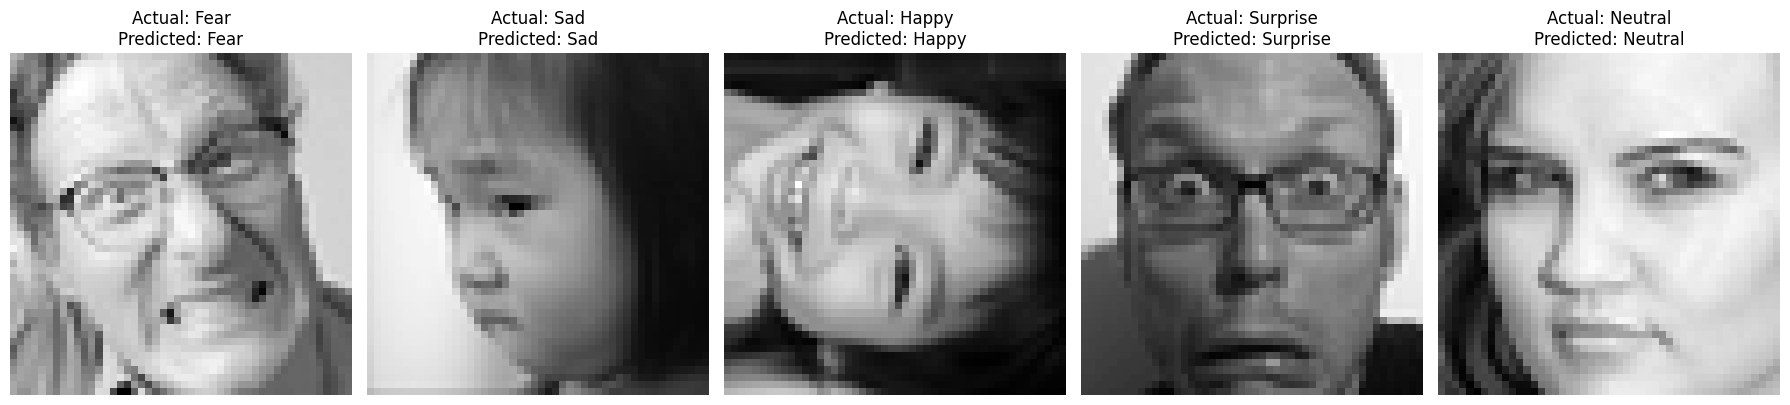

Correct Predictions: 5/5
Accuracy on these 5 images: 100.00%


In [ ]:

import matplotlib.pyplot as plt
import torch

class_names = [
    'Angry', 'Disgust', 'Fear', 'Happy',
    'Sad', 'Surprise', 'Neutral'
]

model.eval()

images, labels = next(iter(test_loader))

images = images[:5].to(device)
labels = labels[:5].to(device)

with torch.no_grad():
    outputs = model(images)
    predictions = outputs.argmax(dim=1)

correct = (predictions == labels).sum().item()
accuracy = (correct / len(labels)) * 100

images = images.cpu()
labels = labels.cpu()
predictions = predictions.cpu()

fig, axes = plt.subplots(1, 5, figsize=(18, 4))

for i, ax in enumerate(axes):
    ax.imshow(images[i].squeeze(), cmap='gray')

    actual = class_names[labels[i].item()]
    predicted = class_names[predictions[i].item()]

    ax.set_title(
        f"Actual: {actual}\nPredicted: {predicted}"
    )
    ax.axis('off')

plt.tight_layout()
plt.show()

print(f"Correct Predictions: {correct}/5")
print(f"Accuracy on these 5 images: {accuracy:.2f}%")
